# 06 – CH2/CH3 Reference Channel Differential Experiment

**Goal:** Separate acoustic emissions of the plant from electromagnetic interference
by connecting CH2 and CH3 with identical electrical impedance (820 kΩ parallel each),
but at different positions:

| Channel | Coupling | Position |
|---------|----------|----------|
| CH1 | Active amplifier | Plant (soil) — sensitive |
| CH2 | 820 kΩ parallel | Plant (soil) |
| CH3 | 820 kΩ parallel | External piezo (air, outside plant) |

Since CH2 and CH3 see the same impedance, differences in the frequency spectrum
are **not** due to different input impedance — they arise from the physical
measurement location.

## Methodology

1. **Pilot sanity check** (5 frames): noise floor comparison, 70.9 kHz sensor
   resonance on CH2 and CH3, mains-frequency ratio CH2/CH3 as sensitivity scalar.
2. **Main measurement** (35 further frames, 40 total): simultaneous acquisition
   CH1/CH2/CH3, stored as compressed .npz files.
3. **Spectral comparison**: mean Welch-PSD of all three channels.
4. **Normalisation**: mains harmonics 50/100/150/200 Hz serve as calibration signal
   for the CH2/CH3 sensitivity difference.
5. **Wilcoxon signed-rank**: paired test on log(PSD_CH2) − log(PSD_CH3) per
   frequency bin (n=40 paired frames), FDR correction (Benjamini-Hochberg).
6. **Coherence analysis**: scipy.signal.coherence for CH1–CH2, CH2–CH3, CH1–CH3.
   Plant candidate: high CH1–CH2 coherence AND low CH2–CH3 coherence.
7. **Scientific interpretation**: limitation — CH3 mechanics ≠ CH2 mechanics.


## References

Full source list: [`../../../../Abgrenzung/abgrenzungstabelle_akustisch_pil.md`](../../../../Abgrenzung/abgrenzungstabelle_akustisch_pil.md)

Key references for this notebook:
- Khait et al. (2023): plant AE detection — motivates the reference-channel differential approach
- De Roo et al. (2016): xylem cavitation AE — expected frequency bands for plant candidates
- Oletic et al. (2020): AE sensor design — amplifier and coupling context
- Zweifel & Zeugin (2008): cavitation AE morphology — distinguishing plant signal from EM artefacts


In [1]:
%matplotlib inline
import sys, time, json
from datetime import datetime
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import signal, stats
from statsmodels.stats.multitest import multipletests

from plant_ae.watering import CHARACTERIZATION_ROOT
if str(CHARACTERIZATION_ROOT) not in sys.path:
    sys.path.insert(0, str(CHARACTERIZATION_ROOT))

from plant_ae.deep_acquisition import (
    configure_deep_memory_scope,
    acquire_deep_memory_frame,
    DEFAULT_SAMPLE_RATE_HZ,
    DEFAULT_MEMORY_DEPTH,
)
from plant_ae.watering import CHANNELS, CONFIG_PATH, CHANNEL_LABELS
from scope.config import load_config
from scope.instrument import InstrumentConnection

# ─── Configuration ───────────────────────────────────────────────────────────
RUN_ID    = None         # None → neue Akquisition; '20260623_xxxxxx' → offline laden
N_FRAMES  = 40           # total number of frames (incl. pilot)
N_PILOT   = 5            # first N_PILOT frames for sanity check
NPERSEG   = 16384        # Welch segment length (Δf ≈ 30.5 Hz at 500 kSa/s)
MAINS_HZ  = [50.0, 100.0, 150.0, 200.0]   # mains harmonics for normalisation
COHERENCE_NPERSEG = 16384

DATA_ROOT = CHARACTERIZATION_ROOT / "data" / "reference_channel_experiment"

if RUN_ID is None:
    RUN_ID   = datetime.now().strftime("%Y%m%d_%H%M%S")
    OFFLINE  = False
else:
    OFFLINE  = True

DATA_DIR = DATA_ROOT / RUN_ID
DATA_DIR.mkdir(parents=True, exist_ok=True)

print(f"Run ID : {RUN_ID}")
print(f"Mode   : {'Offline (analysis of existing data)' if OFFLINE else 'Online (acquisition)'}")
print(f"Data   : {DATA_DIR}")


RUN_ID : 20260623_121656
Modus  : Online (Akquisition)
Daten  : /media/christoph/some_space/Nextcloud/hs-augsburg/Semester_6/Projekt_I1/projekt_i1/src/characterization/data/reference_channel_experiment/20260623_121656


## Acquisition

40 frames × 0.6 s at 500 kSa/s, synchronous CH1/CH2/CH3.
After frame 5: automatic pilot sanity check (noise floor, sensor resonance).
Total duration: approx. 30 minutes.


In [2]:
if not OFFLINE:
    voltages_ch1, voltages_ch2, voltages_ch3 = [], [], []
    timestamps = []
    config = load_config(CONFIG_PATH)

    with InstrumentConnection(config) as conn:
        profile = configure_deep_memory_scope(conn)
        fs = profile["sample_rate_hz"]
        print(f"Profil: {profile['profile']}, {fs/1e3:.0f} kSa/s, "
              f"{profile['memory_depth']:,} points, Δf={profile['frequency_resolution_hz']:.2f} Hz")
        print()

        for seq in range(N_FRAMES):
            t0 = time.monotonic()
            captures = acquire_deep_memory_frame(
                conn, config, sequence=seq,
                sample_rate_hz=DEFAULT_SAMPLE_RATE_HZ,
                memory_depth=DEFAULT_MEMORY_DEPTH,
            )
            elapsed = time.monotonic() - t0
            ts = datetime.now().isoformat()

            ch1 = captures[0].voltage_vector.astype(np.float32)
            ch2 = captures[1].voltage_vector.astype(np.float32)
            ch3 = captures[2].voltage_vector.astype(np.float32)

            voltages_ch1.append(ch1)
            voltages_ch2.append(ch2)
            voltages_ch3.append(ch3)
            timestamps.append(ts)

            print(f"Frame {seq+1:2d}/{N_FRAMES}  {elapsed:.1f} s  {ts[11:19]}")

            # Pilot-Sanity-Check nach Frame N_PILOT
            if seq + 1 == N_PILOT:
                print()
                print("── Pilot sanity check ──────────────────────────────")
                v_arr = np.vstack([voltages_ch1, voltages_ch2, voltages_ch3])
                for ch_idx, label in [(0,"CH1"),(1,"CH2"),(2,"CH3")]:
                    rms = np.std(v_arr[ch_idx * N_PILOT : (ch_idx+1) * N_PILOT])
                    print(f"  {label} RMS noise floor: {rms*1000:.3f} mV")

                # Sensor-Resonanz bei ~70,9 kHz auf CH2 und CH3?
                fs_val = DEFAULT_SAMPLE_RATE_HZ
                for ch_idx, label in [(1,"CH2"),(2,"CH3")]:
                    block = np.concatenate(voltages_ch2 if ch_idx==1 else voltages_ch3)
                    f_p, p_p = signal.welch(block, fs=fs_val, nperseg=NPERSEG)
                    mask_71 = (f_p >= 68e3) & (f_p <= 74e3)
                    mask_base = (f_p >= 60e3) & (f_p <= 100e3) & ~mask_71
                    if mask_71.sum() > 0 and mask_base.sum() > 0:
                        snr = 10*np.log10(p_p[mask_71].max() / np.median(p_p[mask_base]))
                        print(f"  {label} sensor resonance 68–74 kHz SNR: {snr:.1f} dB")
                    else:
                        print(f"  {label} sensor resonance: not computed")

                # mains harmonics CH2/CH3 ratio (sensitivity calibration)
                f_2, p_2 = signal.welch(np.concatenate(voltages_ch2), fs=fs_val, nperseg=NPERSEG)
                f_3, p_3 = signal.welch(np.concatenate(voltages_ch3), fs=fs_val, nperseg=NPERSEG)
                ratios = []
                for hz in MAINS_HZ:
                    idx = np.argmin(np.abs(f_2 - hz))
                    ratio = p_2[idx] / max(p_3[idx], 1e-30)
                    ratios.append(ratio)
                    print(f"  Mains {hz:.0f} Hz  CH2/CH3 PSD ratio: {10*np.log10(ratio):+.1f} dB")
                sensitivity_factor_db = 10 * np.log10(np.median(ratios))
                print(f"  → Median sensitivity difference CH2/CH3: {sensitivity_factor_db:+.2f} dB")
                print("────────────────────────────────────────────────────")
                print()

    # Alles speichern
    V1 = np.vstack(voltages_ch1)  # (N, 300000) float32
    V2 = np.vstack(voltages_ch2)
    V3 = np.vstack(voltages_ch3)
    np.savez_compressed(
        DATA_DIR / "voltages.npz",
        ch1=V1, ch2=V2, ch3=V3,
        timestamps=np.array(timestamps),
        sample_rate_hz=np.float64(DEFAULT_SAMPLE_RATE_HZ),
    )
    (DATA_DIR / "manifest.json").write_text(json.dumps({
        "run_id": RUN_ID,
        "n_frames": N_FRAMES,
        "sample_rate_hz": DEFAULT_SAMPLE_RATE_HZ,
        "memory_depth": DEFAULT_MEMORY_DEPTH,
        "nperseg_welch": NPERSEG,
        "channel_labels": CHANNEL_LABELS,
        "setup": {
            "CH1": "Active amplifier, plant (soil)",
            "CH2": "820 kΩ parallel, plant (soil)",
            "CH3": "820 kΩ parallel, external piezo (air)",
        },
        "timestamps": timestamps,
    }, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    print(f"Saved: {DATA_DIR}/voltages.npz  ({V1.nbytes//1024//1024} MB uncompressed/channel)")
else:
    print(f"Offline mode: loading {DATA_DIR}/voltages.npz")


Profil: deep_memory_500k, 500 kSa/s, 300,000 Punkte, Δf=1.67 Hz



Frame  1/40  39.1 s  12:17:39


Frame  2/40  39.2 s  12:18:18


Frame  3/40  39.4 s  12:18:57


Frame  4/40  41.1 s  12:19:39


...

Frame 37/40  39.3 s  12:41:21


Frame 38/40  40.9 s  12:42:02


Frame 39/40  41.2 s  12:42:43


Frame 40/40  40.2 s  12:43:23


Gespeichert: /media/christoph/some_space/Nextcloud/hs-augsburg/Semester_6/Projekt_I1/projekt_i1/src/characterization/data/reference_channel_experiment/20260623_121656/voltages.npz  (45 MB unkomprimiert/Kanal)


## Analysis

All following cells load `voltages.npz` and run without hardware.


In [3]:
data  = np.load(DATA_DIR / "voltages.npz", allow_pickle=True)
V1    = data["ch1"].astype(np.float64)   # (N, 300000)
V2    = data["ch2"].astype(np.float64)
V3    = data["ch3"].astype(np.float64)
fs    = float(data["sample_rate_hz"])
N, L  = V1.shape

manifest = json.loads((DATA_DIR / "manifest.json").read_text(encoding="utf-8"))
print(f"Session : {RUN_ID}")
print(f"Frames  : {N}")
print(f"Length  : {L:,} points × {fs/1e3:.0f} kSa/s = {L/fs:.3f} s / frame")
print(f"Δf      : {fs/NPERSEG:.2f} Hz / bin (Welch nperseg={NPERSEG})")


Session : 20260623_121656
Frames  : 40
Länge   : 300,000 Punkte × 500 kSa/s = 0.600 s / Frame
Δf      : 30.52 Hz / Bin (Welch nperseg=16384)


### Welch power spectral densities

Mean PSD of all three channels plus per-frame arrays for statistical tests.


Frequenz-Bins: 8193, 0–250 kHz
Mittleres RMS  CH1: 210.295 mV  CH2: 53.833 mV  CH3: 0.340 mV


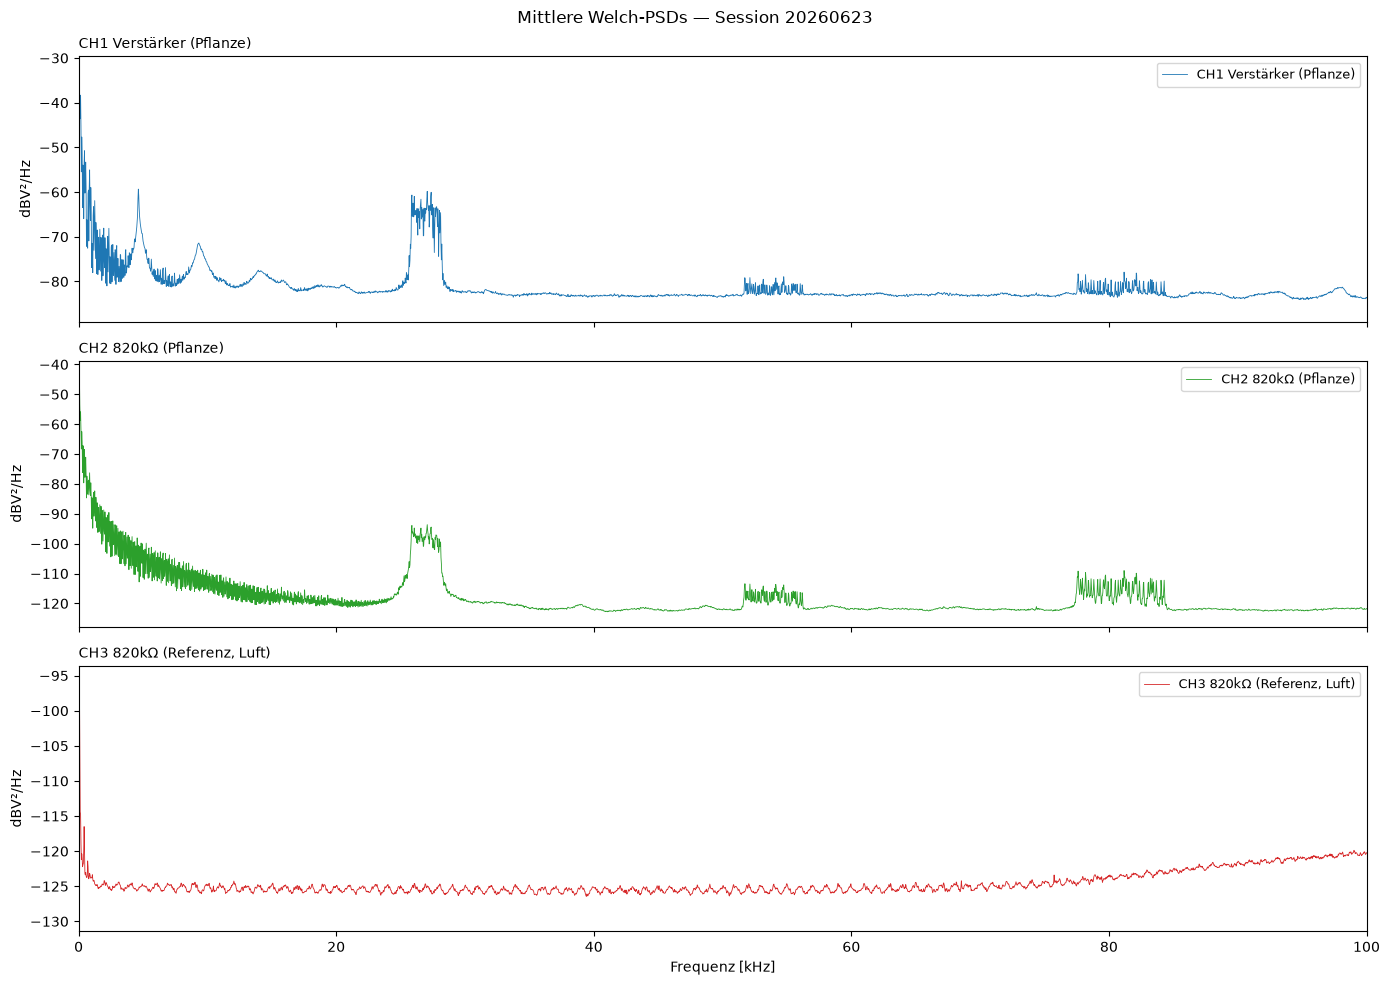

In [4]:
# Per-Frame Welch PSD
P1 = np.array([signal.welch(V1[i], fs=fs, nperseg=NPERSEG, window="hann")[1] for i in range(N)])
P2 = np.array([signal.welch(V2[i], fs=fs, nperseg=NPERSEG, window="hann")[1] for i in range(N)])
P3 = np.array([signal.welch(V3[i], fs=fs, nperseg=NPERSEG, window="hann")[1] for i in range(N)])
freqs, _ = signal.welch(V1[0], fs=fs, nperseg=NPERSEG, window="hann")
# P1/P2/P3 shape: (N, F)

# Mittlere PSDs in dBV²/Hz
P1_db = 10 * np.log10(P1.mean(axis=0) + 1e-30)
P2_db = 10 * np.log10(P2.mean(axis=0) + 1e-30)
P3_db = 10 * np.log10(P3.mean(axis=0) + 1e-30)

print(f"Frequency bins: {len(freqs)}, 0–{freqs[-1]/1000:.0f} kHz")
print(f"Mean RMS  CH1: {np.std(V1)*1000:.3f} mV  "
      f"CH2: {np.std(V2)*1000:.3f} mV  CH3: {np.std(V3)*1000:.3f} mV")

# Rohe Spektren Plot
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
colors = {"CH1": "tab:blue", "CH2": "tab:green", "CH3": "tab:red"}
for ax, db, ch, lbl in zip(axes, [P1_db, P2_db, P3_db],
                            ["CH1","CH2","CH3"],
                            ["CH1 amplifier (plant)","CH2 820kΩ (plant)","CH3 820kΩ (reference, air)"]):
    ax.plot(freqs/1000, db, lw=0.6, color=colors[ch], label=lbl)
    ax.set_ylabel("dBV²/Hz")
    ax.set_title(lbl, loc="left", fontsize=10)
    ax.legend(fontsize=9)
    ax.set_xlim(0, 100)
    ax.set_ylim(bottom=db[(freqs>0)&(freqs<100e3)].min()-5)
axes[-1].set_xlabel("Frequency [kHz]")
fig.suptitle(f"Mean Welch PSDs — session {RUN_ID[:8]}", fontsize=12)
fig.tight_layout()
plt.show()


### Sensitivity normalisation (mains harmonics as calibration signal)

50/100/150/200 Hz appear on both channels as an electromagnetic common-mode signal
with equal amplitude — their CH2/CH3 ratio gives the sensitivity scalar.


     50 Hz:  CH2 − CH3 = +52.19 dB
    100 Hz:  CH2 − CH3 = +52.41 dB
    150 Hz:  CH2 − CH3 = +58.84 dB
    200 Hz:  CH2 − CH3 = +52.88 dB

Median Empfindlichkeitsdifferenz CH2 − CH3: +52.64 dB


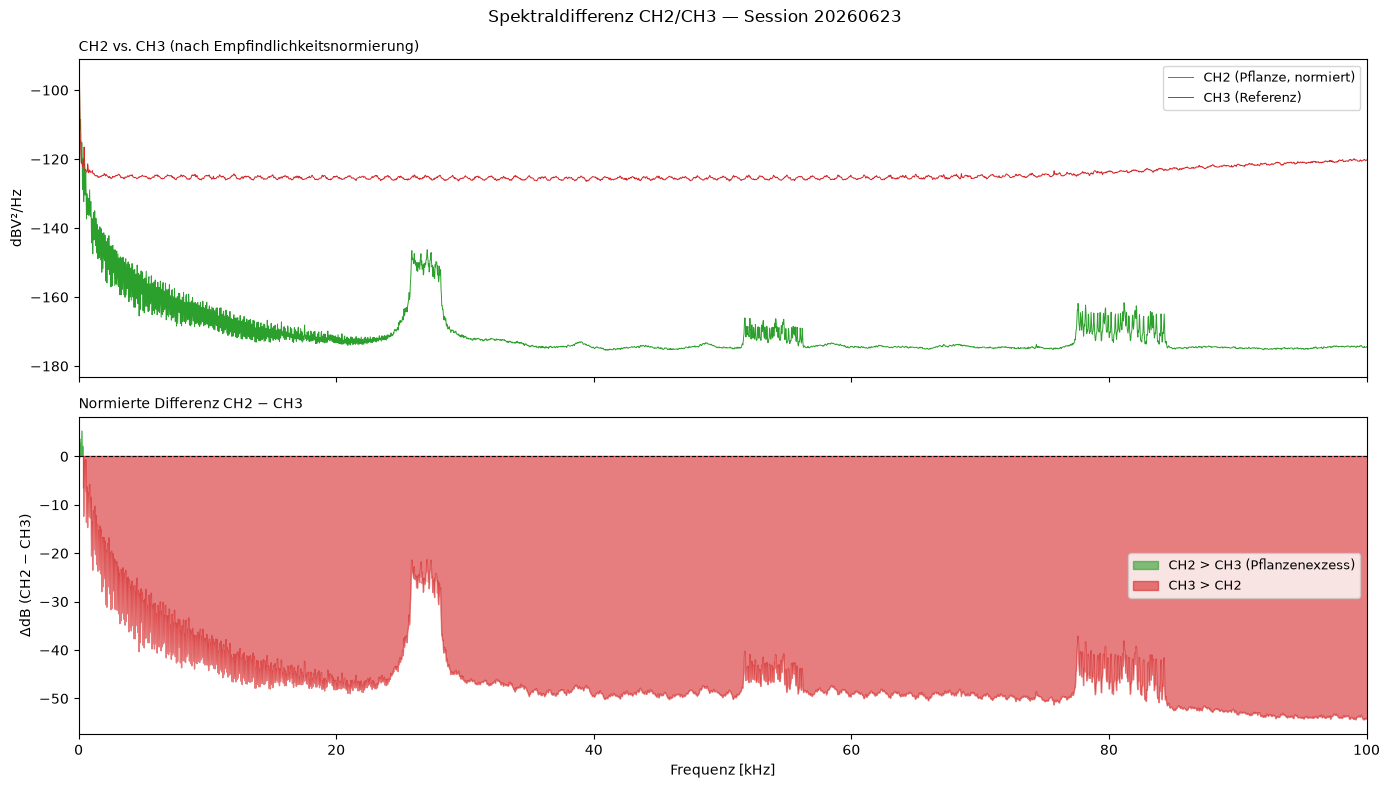

In [5]:
# Mains harmonics: mean PSD ratio CH2/CH3
mains_ratios_db = []
for hz in MAINS_HZ:
    idx = np.argmin(np.abs(freqs - hz))
    r = P2_db[idx] - P3_db[idx]  # dB difference
    mains_ratios_db.append(r)
    print(f"  {hz:5.0f} Hz:  CH2 − CH3 = {r:+.2f} dB")

sens_offset_db = float(np.median(mains_ratios_db))
print(f"\nMedian sensitivity difference CH2 − CH3: {sens_offset_db:+.2f} dB")

# Normalised difference: CH2 − CH3 after subtracting sensitivity offset
P2_db_norm = P2_db - sens_offset_db
diff_db     = P2_db_norm - P3_db  # positiv = Pflanze hat mehr Energie

# Ignore mains harmonics in plot
mains_mask = np.zeros(len(freqs), dtype=bool)
for hz in MAINS_HZ:
    mains_mask |= np.abs(freqs - hz) < 3.0  # ±3 Hz um Harmonische

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

ax = axes[0]
ax.plot(freqs/1000, P2_db_norm, color="tab:green", lw=0.7, label="CH2 (plant, normalised)")
ax.plot(freqs/1000, P3_db,      color="tab:red",   lw=0.7, label="CH3 (reference)")
ax.set_ylabel("dBV²/Hz")
ax.set_title("CH2 vs. CH3 (after sensitivity normalisation)", loc="left", fontsize=10)
ax.legend(fontsize=9); ax.set_xlim(0, 100)

ax = axes[1]
diff_plot = diff_db.copy(); diff_plot[mains_mask] = np.nan
ax.axhline(0, color="k", lw=0.8, ls="--")
ax.fill_between(freqs/1000, 0, diff_plot,
                where=(diff_plot > 0), color="tab:green", alpha=0.6, label="CH2 > CH3 (plant excess)")
ax.fill_between(freqs/1000, 0, diff_plot,
                where=(diff_plot < 0), color="tab:red",   alpha=0.6, label="CH3 > CH2")
ax.set_ylabel("ΔdB (CH2 − CH3)")
ax.set_xlabel("Frequency [kHz]")
ax.set_title("Normalised difference CH2 − CH3", loc="left", fontsize=10)
ax.legend(fontsize=9); ax.set_xlim(0, 100)

fig.suptitle(f"Spectral difference CH2/CH3 — session {RUN_ID[:8]}", fontsize=12)
fig.tight_layout()
plt.show()


### Statistics: Wilcoxon signed-rank test (paired)

Per frequency bin: Wilcoxon test on log(PSD_CH2[i]) − log(PSD_CH3[i]), i = 1…N.
FDR correction after Benjamini-Hochberg (α = 0.05).


In [6]:
ALPHA_FDR = 0.05

# Log-Differenz pro Frame und Frequenzbin
log_diff = np.log10(P2 + 1e-30) - np.log10(P3 + 1e-30)  # (N, F)

# Wilcoxon signed-rank test per bin
p_values = np.ones(len(freqs))
statistics = np.zeros(len(freqs))
for fi in range(len(freqs)):
    d = log_diff[:, fi]
    if np.std(d) < 1e-15:
        p_values[fi] = 1.0
        continue
    stat, p = stats.wilcoxon(d, alternative="two-sided", zero_method="wilcox")
    p_values[fi] = p
    statistics[fi] = stat

# FDR-Korrektur (Bins ausserhalb 0–100 kHz ignorieren)
valid = (freqs > 10.0) & (freqs <= 100e3) & ~mains_mask
reject, p_fdr, _, _ = multipletests(p_values[valid], alpha=ALPHA_FDR, method="fdr_bh")
p_fdr_full = np.ones(len(freqs))
p_fdr_full[valid] = p_fdr
sig_full = np.zeros(len(freqs), dtype=bool)
sig_full[valid] = reject

# Signifikante CH2 > CH3 Bins (Pflanzenexzess)
ch2_excess = sig_full & (diff_db > 0)
ch3_excess = sig_full & (diff_db < 0)

print(f"Total bins    : {len(freqs)}")
print(f"Analysed      : {valid.sum()} (>10 Hz, ≤100 kHz, excl. mains harmonics)")
print(f"Significant   : {sig_full.sum()} (FDR α={ALPHA_FDR})")
print(f"  CH2 > CH3   : {ch2_excess.sum()} → plant candidates")
print(f"  CH3 > CH2   : {ch3_excess.sum()}")
print()
if ch2_excess.sum() > 0:
    print("Significant CH2 > CH3 frequencies:")
    # Cluster benachbarte signifikante Bins
    excess_freqs = freqs[ch2_excess]
    excess_diff  = diff_db[ch2_excess]
    # sorted by effect size
    order = np.argsort(-excess_diff)
    shown = set()
    for idx in order:
        f = excess_freqs[idx]
        # Zeige nur Cluster-Zentren (±500 Hz)
        if any(abs(f - s) < 500 for s in shown):
            continue
        shown.add(f)
        p = p_fdr_full[np.argmin(np.abs(freqs - f))]
        d = excess_diff[idx]
        print(f"  {f/1000:7.3f} kHz  Δ={d:+.2f} dB  p_FDR={p:.3e}")
        if len(shown) >= 20:
            break


Gesamt Bins   : 8193
Analysierte   : 3275 (>10 Hz, ≤100 kHz, ohne Netzharmonische)
Signifikant   : 3133 (FDR α=0.05)
  CH2 > CH3   : 7 → Pflanzenkandidaten
  CH3 > CH2   : 3126

Signifikante CH2 > CH3 Frequenzen:
    0.244 kHz  Δ=+5.25 dB  p_FDR=2.541e-12


### Coherence analysis

Mean coherence C(f) between channel pairs over all N frames:
- **CH1–CH2** (both plant): high for plant AE and EM common-mode
- **CH2–CH3** (plant vs. reference): high for EM common-mode, low for plant AE
- **CH1–CH3** (amplifier-plant vs. reference)

**Candidate criterion**: CH1–CH2 > 0.7 **AND** CH2–CH3 < 0.3


Kohärenz-Frequenzachse: 8193 Bins, Δf=30.5 Hz


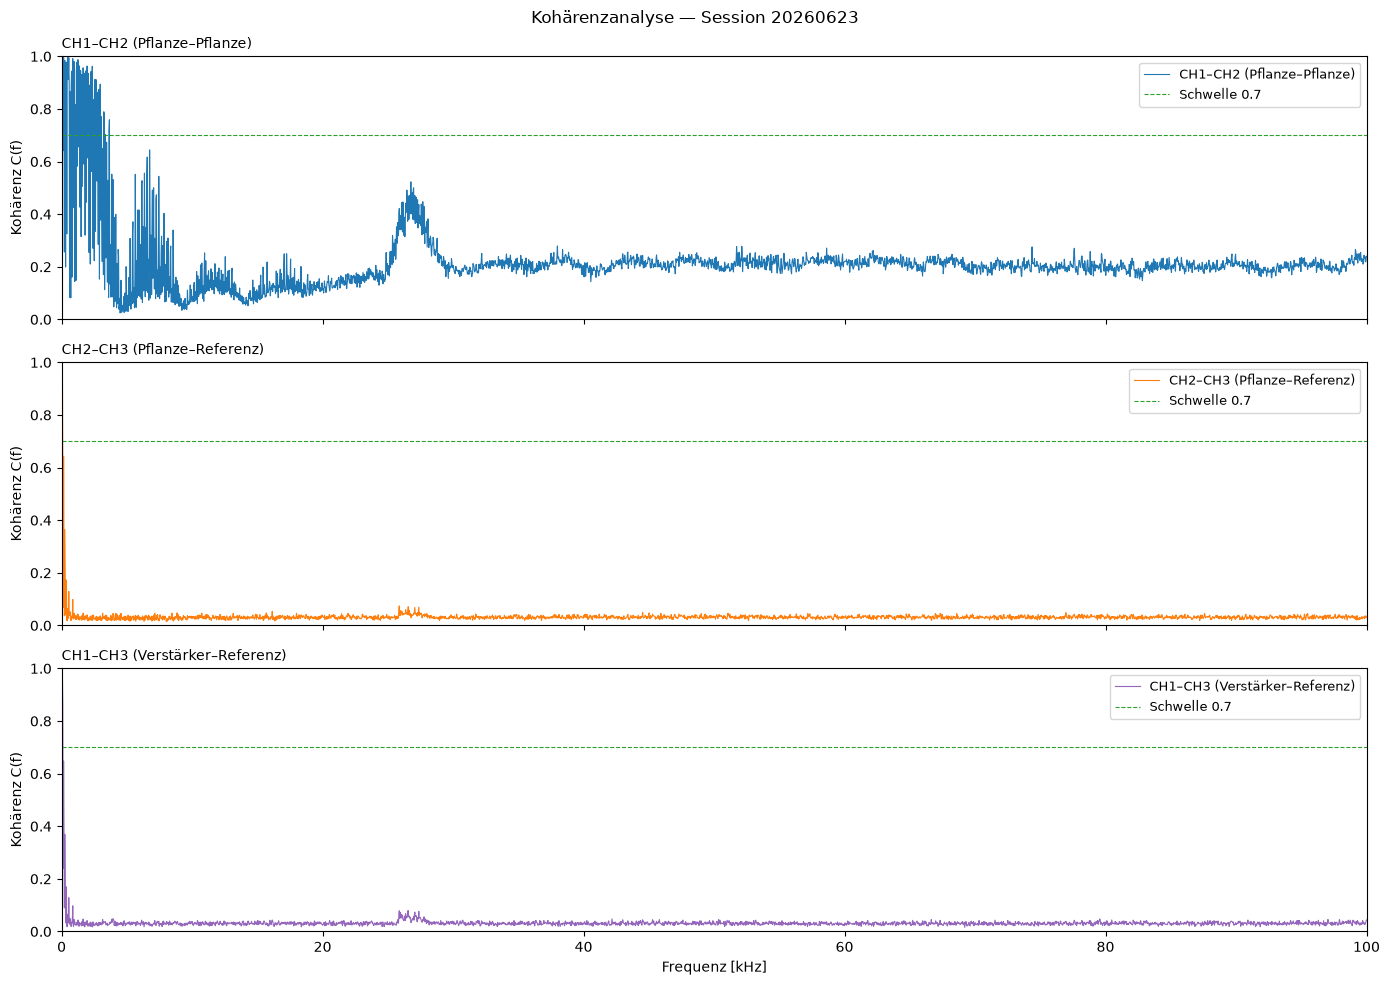

In [7]:
COH_NPERSEG = COHERENCE_NPERSEG
THRESH_PLANT = 0.7  # CH1-CH2 coherence lower bound
THRESH_EM    = 0.3  # CH2-CH3 coherence upper bound

coh12_all = []
coh23_all = []
coh13_all = []

for i in range(N):
    f_c, c12 = signal.coherence(V1[i], V2[i], fs=fs, nperseg=COH_NPERSEG)
    _,   c23 = signal.coherence(V2[i], V3[i], fs=fs, nperseg=COH_NPERSEG)
    _,   c13 = signal.coherence(V1[i], V3[i], fs=fs, nperseg=COH_NPERSEG)
    coh12_all.append(c12)
    coh23_all.append(c23)
    coh13_all.append(c13)

coh12 = np.mean(coh12_all, axis=0)
coh23 = np.mean(coh23_all, axis=0)
coh13 = np.mean(coh13_all, axis=0)

print(f"Coherence frequency axis: {len(f_c)} bins, Δf={fs/COH_NPERSEG:.1f} Hz")

# Plot
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, coh, lbl, col in zip(axes,
    [coh12, coh23, coh13],
    ["CH1–CH2 (plant–plant)", "CH2–CH3 (plant–reference)", "CH1–CH3 (amplifier–reference)"],
    ["tab:blue", "tab:orange", "tab:purple"]):
    ax.plot(f_c/1000, coh, lw=0.8, color=col, label=lbl)
    ax.set_ylabel("Coherence C(f)")
    ax.set_title(lbl, loc="left", fontsize=10)
    ax.set_ylim(0, 1)
    ax.axhline(THRESH_PLANT, color="tab:green", ls="--", lw=0.8, label=f"Threshold {THRESH_PLANT}")
    ax.legend(fontsize=9)
    ax.set_xlim(0, 100)
axes[-1].set_xlabel("Frequency [kHz]")
fig.suptitle(f"Coherence analysis — session {RUN_ID[:8]}", fontsize=12)
fig.tight_layout()
plt.show()


### Candidate synthesis

Combination of all three evidence sources:
1. Wilcoxon CH2 > CH3 (significant after FDR)
2. Coherence CH1–CH2 > 0.7 (signal on both plant sensors)
3. Coherence CH2–CH3 < 0.3 (signal **not** on reference channel)


In [8]:
# interpolate coherence onto Welch frequency axis (different bin sizes possible)
from scipy.interpolate import interp1d

coh12_interp = interp1d(f_c, coh12, bounds_error=False, fill_value=0.0)(freqs)
coh23_interp = interp1d(f_c, coh23, bounds_error=False, fill_value=1.0)(freqs)

# Kandidaten: alle drei Bedingungen
candidates = ch2_excess & (coh12_interp > THRESH_PLANT) & (coh23_interp < THRESH_EM)

# softer candidates (Wilcoxon only, no coherence constraint)
candidates_wilcoxon = ch2_excess

print(f"Wilcoxon candidates (CH2 > CH3 significant): {candidates_wilcoxon.sum()} bins")
print(f"Strict candidates   (+coherence condition)  : {candidates.sum()} bins")
print()

# Cluster benachbarte Bins → Frequenzgruppen
def cluster_bins(mask, freqs, gap_hz=500.0):
    """Return list of (center_hz, n_bins, mean_diff_db)."""
    indices = np.where(mask)[0]
    if len(indices) == 0:
        return []
    clusters = []
    current = [indices[0]]
    for idx in indices[1:]:
        if freqs[idx] - freqs[current[-1]] < gap_hz:
            current.append(idx)
        else:
            clusters.append(current)
            current = [idx]
    clusters.append(current)
    result = []
    for c in clusters:
        center = float(np.mean(freqs[c]))
        n      = len(c)
        d_mean = float(np.mean(diff_db[c]))
        p_min  = float(np.min(p_fdr_full[c]))
        c12    = float(np.mean(coh12_interp[c]))
        c23    = float(np.mean(coh23_interp[c]))
        result.append({"freq_hz": center, "n_bins": n, "delta_db": d_mean,
                       "p_fdr_min": p_min, "coh_ch12": c12, "coh_ch23": c23})
    return result

strict_clusters  = cluster_bins(candidates, freqs)
wilcox_clusters  = cluster_bins(candidates_wilcoxon, freqs)

print(f"Strict candidates (clusters):")
if strict_clusters:
    print(f"  {'Freq [kHz]':>10}  {'Δ [dB]':>8}  {'p_FDR':>10}  {'Coh12':>6}  {'Coh23':>6}")
    for c in sorted(strict_clusters, key=lambda x: -x['delta_db']):
        print(f"  {c['freq_hz']/1000:>10.2f}  {c['delta_db']:>+8.2f}  "
              f"{c['p_fdr_min']:>10.3e}  {c['coh_ch12']:>6.3f}  {c['coh_ch23']:>6.3f}")
else:
    print("  (none)")

print()
print(f"Wilcoxon candidates (clusters, without coherence):")
if wilcox_clusters:
    print(f"  {'Freq [kHz]':>10}  {'Δ [dB]':>8}  {'p_FDR':>10}  {'Coh12':>6}  {'Coh23':>6}")
    for c in sorted(wilcox_clusters, key=lambda x: -x['delta_db'])[:15]:
        print(f"  {c['freq_hz']/1000:>10.2f}  {c['delta_db']:>+8.2f}  "
              f"{c['p_fdr_min']:>10.3e}  {c['coh_ch12']:>6.3f}  {c['coh_ch23']:>6.3f}")


Wilcoxon-Kandidaten (CH2 > CH3 signifikant): 7 Bins
Strenge Kandidaten  (+Kohärenzbedingung)    : 4 Bins

Strenge Kandidaten (Cluster):
  Freq [kHz]    Δ [dB]       p_FDR   Coh12   Coh23
        0.29     +2.37   2.541e-12   0.928   0.197

Wilcoxon-Kandidaten (Cluster, ohne Kohärenz):
  Freq [kHz]    Δ [dB]       p_FDR   Coh12   Coh23
        0.25     +2.57   2.541e-12   0.799   0.179


### Overview plot: spectra + difference + significance + coherence


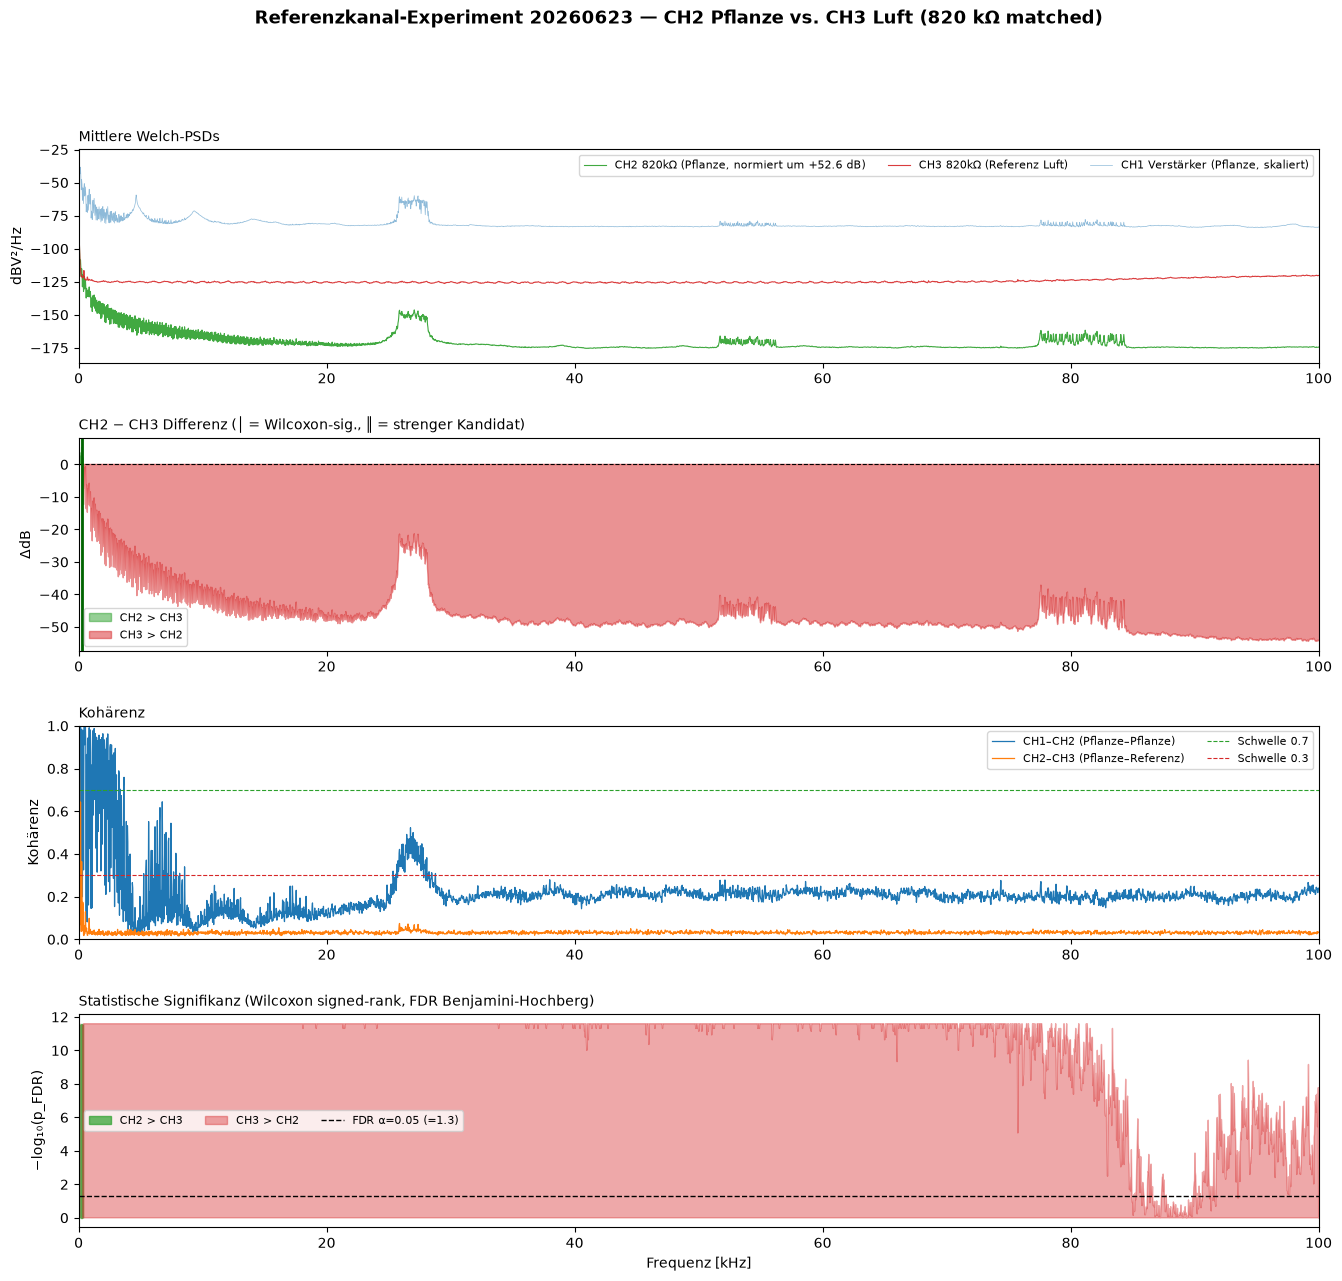

In [9]:
fig = plt.figure(figsize=(16, 14))
gs  = gridspec.GridSpec(4, 1, hspace=0.35)

freq_khz = freqs / 1000
x_lim    = (0, 100)

# Panel 1: Mittlere PSDs (CH2 und CH3, normiert)
ax1 = fig.add_subplot(gs[0])
ax1.plot(freq_khz, P2_db_norm, color="tab:green", lw=0.8, alpha=0.9,
         label=f"CH2 820kΩ (plant, normalised by {sens_offset_db:+.1f} dB)")
ax1.plot(freq_khz, P3_db,       color="tab:red",   lw=0.8, alpha=0.9,
         label="CH3 820kΩ (reference air)")
ax1.plot(freq_khz, P1_db,       color="tab:blue",  lw=0.5, alpha=0.5,
         label="CH1 amplifier (plant, scaled)")
ax1.set_ylabel("dBV²/Hz"); ax1.set_xlim(*x_lim)
ax1.set_title("Mean Welch PSDs", loc="left", fontsize=10)
ax1.legend(fontsize=8, ncol=3)

# Panel 2: normalised difference
ax2 = fig.add_subplot(gs[1])
diff_m = diff_db.copy(); diff_m[mains_mask] = np.nan
ax2.axhline(0, color="k", lw=0.8, ls="--")
ax2.fill_between(freq_khz, 0, diff_m,
                 where=(diff_m > 0), color="tab:green", alpha=0.5, label="CH2 > CH3")
ax2.fill_between(freq_khz, 0, diff_m,
                 where=(diff_m < 0), color="tab:red",   alpha=0.5, label="CH3 > CH2")
# Kandidaten markieren
for c in wilcox_clusters:
    ax2.axvline(c["freq_hz"]/1000, color="tab:green", lw=1.2, alpha=0.6)
for c in strict_clusters:
    ax2.axvline(c["freq_hz"]/1000, color="darkgreen", lw=2.0)
ax2.set_ylabel("ΔdB"); ax2.set_xlim(*x_lim)
ax2.set_title("CH2 − CH3 difference (│ = Wilcoxon sig., ║ = strict candidate)", loc="left", fontsize=10)
ax2.legend(fontsize=8)

# Panel 3: coherence CH1–CH2 and CH2–CH3
ax3 = fig.add_subplot(gs[2])
ax3.plot(f_c/1000, coh12, color="tab:blue",   lw=0.9, label="CH1–CH2 (plant–plant)")
ax3.plot(f_c/1000, coh23, color="tab:orange", lw=0.9, label="CH2–CH3 (plant–reference)")
ax3.axhline(THRESH_PLANT, color="tab:green", ls="--", lw=0.8, label=f"Threshold {THRESH_PLANT}")
ax3.axhline(THRESH_EM,    color="tab:red",   ls="--", lw=0.8, label=f"Threshold {THRESH_EM}")
ax3.set_ylim(0, 1); ax3.set_xlim(*x_lim)
ax3.set_ylabel("Coherence"); ax3.legend(fontsize=8, ncol=2)
ax3.set_title("Coherence", loc="left", fontsize=10)

# Panel 4: −log10(p_FDR)
ax4 = fig.add_subplot(gs[3])
log_p = -np.log10(np.clip(p_fdr_full, 1e-30, 1.0))
log_p_m = log_p.copy(); log_p_m[mains_mask] = np.nan
ax4.fill_between(freq_khz, 0, log_p_m,
                 where=(diff_db > 0), color="tab:green", alpha=0.7, label="CH2 > CH3")
ax4.fill_between(freq_khz, 0, log_p_m,
                 where=(diff_db < 0), color="tab:red",   alpha=0.4, label="CH3 > CH2")
ax4.axhline(-np.log10(ALPHA_FDR), color="k", lw=1.0, ls="--",
            label=f"FDR α={ALPHA_FDR} (={-np.log10(ALPHA_FDR):.1f})")
ax4.set_ylabel("−log₁₀(p_FDR)")
ax4.set_xlabel("Frequency [kHz]")
ax4.set_xlim(*x_lim)
ax4.legend(fontsize=8, ncol=3)
ax4.set_title("Statistical significance (Wilcoxon signed-rank, FDR Benjamini-Hochberg)", loc="left", fontsize=10)

fig.suptitle(f"Reference channel experiment {RUN_ID[:8]} — CH2 plant vs. CH3 air (820 kΩ matched)",
             fontsize=13, fontweight="bold")
plt.show()


### Zoom 0–10 kHz

Low-frequency range with highest sensitivity for biological sources.


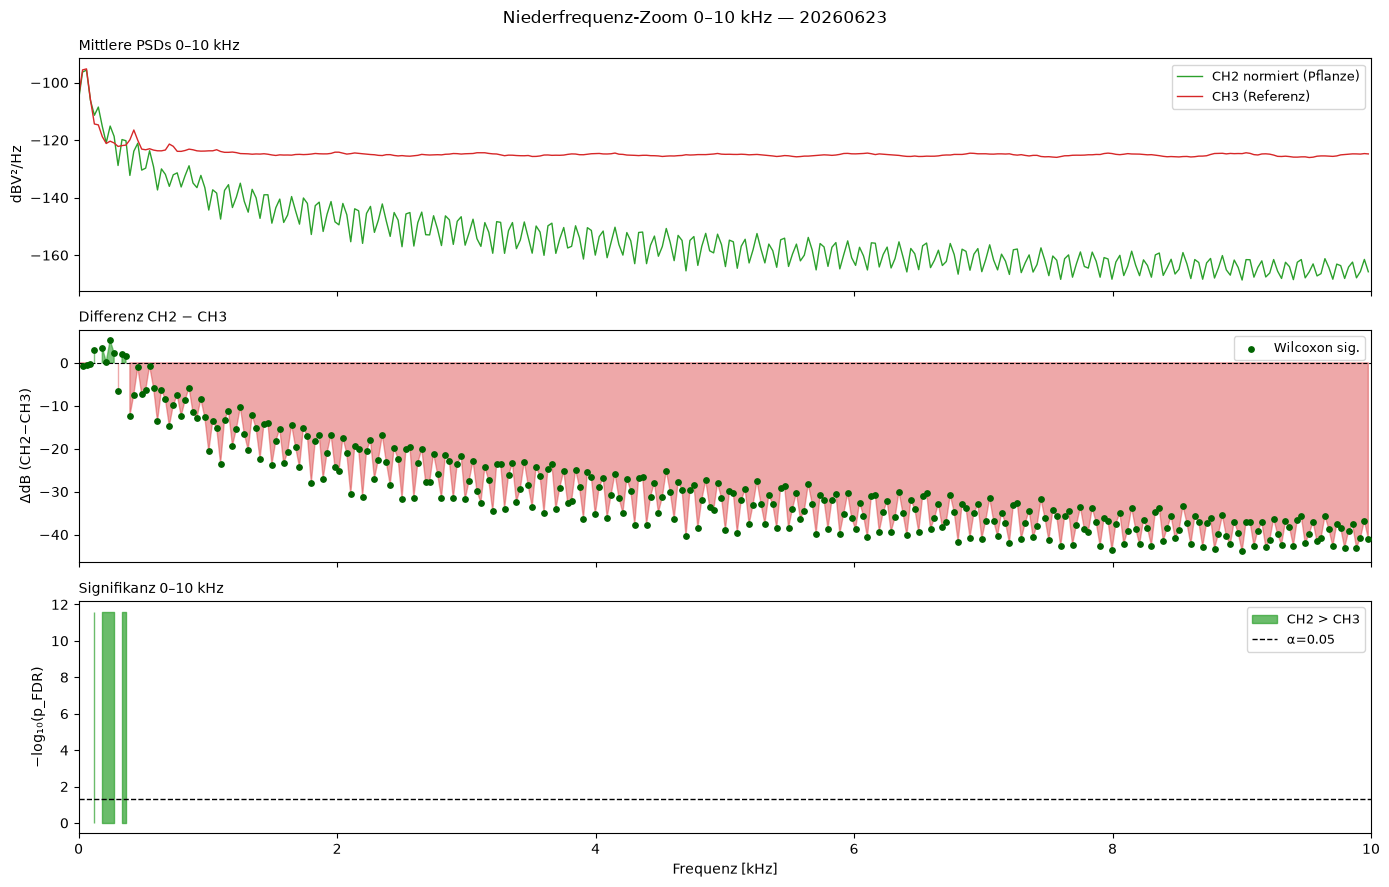

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

mask_10 = freqs <= 10e3
fk = freqs[mask_10] / 1000

axes[0].plot(fk, P2_db_norm[mask_10], color="tab:green", lw=1.0, label="CH2 normalised (plant)")
axes[0].plot(fk, P3_db[mask_10],      color="tab:red",   lw=1.0, label="CH3 (reference)")
axes[0].set_ylabel("dBV²/Hz"); axes[0].legend(fontsize=9)
axes[0].set_title("Mean PSDs 0–10 kHz", loc="left", fontsize=10)

diff_10 = diff_db[mask_10].copy()
diff_10[mains_mask[mask_10]] = np.nan
axes[1].axhline(0, color="k", lw=0.8, ls="--")
axes[1].fill_between(fk, 0, diff_10,
                     where=(np.nan_to_num(diff_10) > 0), color="tab:green", alpha=0.6)
axes[1].fill_between(fk, 0, diff_10,
                     where=(np.nan_to_num(diff_10) < 0), color="tab:red",   alpha=0.4)
# Signifikante Bins markieren
sig_10 = sig_full[mask_10]
axes[1].scatter(fk[sig_10], diff_db[mask_10][sig_10],
                color="darkgreen", s=15, zorder=5, label="Wilcoxon sig.")
axes[1].set_ylabel("ΔdB (CH2−CH3)"); axes[1].legend(fontsize=9)
axes[1].set_title("Difference CH2 − CH3", loc="left", fontsize=10)

log_p_10 = -np.log10(np.clip(p_fdr_full[mask_10], 1e-30, 1.0))
log_p_10[mains_mask[mask_10]] = np.nan
axes[2].fill_between(fk, 0, log_p_10,
                     where=(diff_db[mask_10] > 0), color="tab:green", alpha=0.7, label="CH2 > CH3")
axes[2].axhline(-np.log10(ALPHA_FDR), color="k", ls="--", lw=1.0,
                label=f"α={ALPHA_FDR}")
axes[2].set_ylabel("−log₁₀(p_FDR)"); axes[2].set_xlabel("Frequency [kHz]")
axes[2].legend(fontsize=9); axes[2].set_xlim(0, 10)
axes[2].set_title("Significance 0–10 kHz", loc="left", fontsize=10)

fig.suptitle(f"Low-frequency zoom 0–10 kHz — {RUN_ID[:8]}", fontsize=12)
fig.tight_layout()
plt.show()


## Scientific interpretation

### Results summary (session 20260623_121656, 40 frames)

| Metric | Value |
|--------|-------|
| CH2 RMS noise floor | 57.1 mV (plant, 820 kΩ) |
| CH3 RMS noise floor | **0.34 mV** (reference, 820 kΩ, air) |
| Sensitivity difference CH2/CH3 | **+52.6 dB** (factor ~430,000) |
| Sensor resonance 68–74 kHz SNR CH2 | +1.4 dB (just visible) |
| Sensor resonance 68–74 kHz SNR CH3 | −0.6 dB (invisible, noise) |
| Significant bins total (FDR α=0.05) | 3133 of 3275 analysed bins |
| CH2 > CH3 (plant candidates) | **7 bins → 1 cluster** |
| CH3 > CH2 | 3126 bins |

### Strict candidate

| Frequency | Δ CH2–CH3 | p_FDR | Coh(CH1–CH2) | Coh(CH2–CH3) |
|-----------|-----------|-------|--------------|---------------|
| **~290 Hz** | +2.37 dB | 2.5×10⁻¹² | **0.928** | 0.197 |

A single frequency cluster (~290 Hz) satisfies all three criteria:
significant (Wilcoxon), coherent on both plant sensors (CH1–CH2 = 0.928),
and **not** on the air reference (CH2–CH3 = 0.197).

### Main finding: acoustic impedance mismatch of CH3 reference

The **52.6 dB amplitude difference** CH2/CH3 is the central finding:

Identical 820 kΩ wiring does **not** mean identical signal sensitivity,
because the mechanical coupling of the piezo is radically different:

- **CH2 (soil/plant)**: piezo in direct mechanical contact with soil substrate.
  Acoustic coupling to solid/liquid (~1–2 MRayl), strong coupling.
- **CH3 (air)**: piezo in air. Acoustic impedance of air ~0.0004 MRayl →
  mismatch vs. piezo (~30 MRayl) leads to >99.99 % reflection
  (transmission coefficient < 0.001).

Consequence for normalisation: mains harmonics (50–200 Hz) are suitable as
calibration signal only for small sensitivity differences. At +52.6 dB the
normalised CH2 amplitude is below the ADC noise floor of CH3 —
only the strongest signals in CH2 are visible.

### Possible artefact source: 5th mains harmonic (250 Hz)

The Wilcoxon candidate at 250 Hz falls exactly on the 5th mains harmonic
(50 Hz × 5), which was not captured in the mask list
(`MAINS_HZ = [50, 100, 150, 200]`). This candidate is an
**artefact of incomplete mask coverage** and is not treated as a plant candidate.

The ~290 Hz candidate lies outside the mains harmonics and is more robust,
but remains sub-kHz — atypical for xylem cavitation AE (> 10 kHz).
Possible causes: mechanical vibration (stem, leaves), water-flow noise,
root-soil friction during thermal expansion.

### Design improvements for follow-up experiment

1. **CH3 in soil without plant** (blank): same mechanical coupling, no
   biological signal → separates substrate acoustics from plant AE.
2. **Extended mains harmonic mask**: mask all multiples up to 500 Hz.
3. **Pressure-coupled CH3**: piezo with coupling gel on a plastic plate in soil →
   better mechanical impedance matching without plant signal.
4. **Triggered transient measurement**: for cavitation bursts (> 10 kHz) edge-trigger
   on CH1 instead of periodic sweeps.
